# ResNet50 Attention Experiments — CS3807 (Colab)
All Python code is in this notebook. Plots save to `/content/drive/MyDrive/attention_experiment_outputs/plots/`; metrics save alongside. No theory answers.

## PDF requirements implemented
- TensorFlow Flowers; 224×224 RGB; ImageNet ResNet50 preprocessing; identical stratified 70:15:15 split and augmentation.
- ImageNet ResNet50, five-class head, categorical cross-entropy, freeze then fine-tune.
- Attention types at P3 (after conv4_x): baseline, channel, spatial, channel→spatial, self-attention; plus ECA and CBAM (the required two additional mechanisms) at P3.
- Position ablation P1/P2/P3/P4; P3+P4 multi-position; channel→spatial vs spatial→channel; spatial kernels 3/5/7.
- Accuracy, macro precision/recall/F1, parameter counts, inference time, learning curves, confusion matrices, performance/complexity plots.
- Visuals: class samples, feature maps, channel weights, spatial attention/overlay, P2/P3/P4 maps, self-attention response, baseline and attention Grad-CAM.

Default: batch 16 GPU/8 CPU, 5 frozen epochs + 2 fine-tuning epochs, mixed precision on GPU, bounded data prefetch, and a free-RAM guard between models. Each comparison uses the same fixed epoch counts and learning rates. The runtime guard preserves the final 10 minutes before 5.5 hours.

The experiment uses one fixed seed to stay within the runtime target. Small accuracy differences are descriptive and should not be treated as statistically decisive.


In [1]:
import time, gc, random, math, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, tensorflow_datasets as tfds
from tensorflow.keras import layers as L, Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
GPU = bool(tf.config.list_physical_devices('GPU'))
if GPU:
    for d in tf.config.list_physical_devices('GPU'):
        try:
            tf.config.experimental.set_memory_growth(d, True)
        except RuntimeError:
            pass
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
BATCH = 16 if GPU else 8
DATA_PARALLEL_CALLS = 2
PREFETCH_BATCHES = 1
FROZEN_EPOCHS = 5
FT_EPOCHS = 2
BUDGET = 5.5 * 3600
T0 = time.time()
from google.colab import drive
drive.mount('/content/drive')
OUT = Path('/content/drive/MyDrive/attention_experiment_outputs')
PLOTS = OUT / 'plots'
CHECKPOINTS = OUT / 'checkpoints'
PLOTS.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)
NAMES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
NC = 5

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.


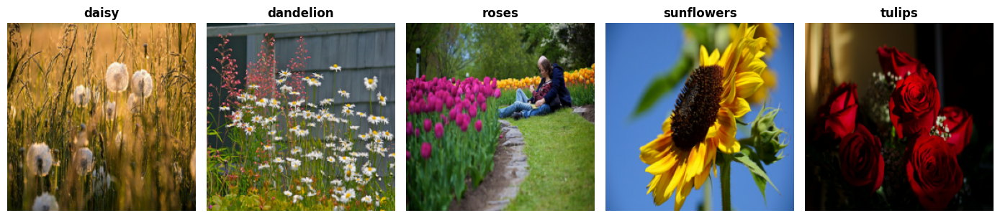

In [2]:
ds = tfds.load('tf_flowers', split='train', as_supervised=True, shuffle_files=False)
ims = []
labs = []
for im, lab in tfds.as_numpy(ds):
    ims.append(tf.image.resize(im, (224, 224), antialias=True).numpy().astype('uint8'))
    labs.append(int(lab))
X = np.stack(ims)
CLASS_LABELS = np.asarray(labs, dtype=np.int32)
del ims, labs, ds
gc.collect()
tr, tmp = train_test_split(np.arange(len(CLASS_LABELS)), test_size=0.3, random_state=SEED, stratify=CLASS_LABELS)
va, te = train_test_split(tmp, test_size=0.5, random_state=SEED, stratify=CLASS_LABELS[tmp])

def dataset(ids, aug=False):
    d = tf.data.Dataset.from_tensor_slices((X[ids], CLASS_LABELS[ids]))
    if aug:
        d = d.shuffle(len(ids), seed=SEED, reshuffle_each_iteration=True)

    def prep(image, label):
        image = tf.cast(image, tf.float32)
        if aug:
            image = tf.image.random_flip_left_right(image, seed=SEED)
            image = tf.image.random_brightness(image, max_delta=12.0, seed=SEED)
            image = tf.clip_by_value(image, 0.0, 255.0)
        image = tf.keras.applications.resnet50.preprocess_input(image)
        return (image, tf.one_hot(label, NC))
    return d.map(prep, num_parallel_calls=DATA_PARALLEL_CALLS).batch(BATCH).prefetch(PREFETCH_BATCHES)
train_ds = dataset(tr, True)
val_ds = dataset(va)
test_ds = dataset(te)
fig, axs = plt.subplots(1, 5, figsize=(14, 3))
for class_id, ax in enumerate(axs):
    image_id = next((index for index in te if CLASS_LABELS[index] == class_id))
    ax.imshow(X[image_id])
    ax.set_title(NAMES[class_id], fontweight='bold')
    ax.axis('off')
fig.tight_layout()
fig.savefig(PLOTS / 'sample_inputs.png', dpi=150)
plt.show()
plt.close(fig)

In [3]:
def ca(x, n):
    c = int(x.shape[-1])
    z = L.GlobalAveragePooling2D(name=n + '_gap')(x)
    z = L.Dense(max(1, c // 16), activation='relu', name=n + '_reduce')(z)
    z = L.Dense(c, activation='sigmoid', name=n + '_weights')(z)
    return L.Multiply(name=n + '_scale')([x, L.Reshape((1, 1, c), name=n + '_reshape')(z)])

def sa(x, k, n):
    avg = L.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True), name=n + '_avg')(x)
    maximum = L.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True), name=n + '_max')(x)
    pooled = L.Concatenate(name=n + '_concat')([avg, maximum])
    mask = L.Conv2D(1, k, padding='same', activation='sigmoid', name=n + '_map')(pooled)
    return L.Multiply(name=n + '_scale')([x, mask])

def cbam(x, k, n):
    channels = int(x.shape[-1])
    reduce = L.Dense(max(1, channels // 16), activation='relu', name=n + '_channel_reduce')
    expand = L.Dense(channels, name=n + '_channel_expand')
    avg = L.GlobalAveragePooling2D(name=n + '_avg_pool')(x)
    maximum = L.GlobalMaxPooling2D(name=n + '_max_pool')(x)
    weights = L.Activation('sigmoid', name=n + '_channel_weights')(L.Add(name=n + '_channel_add')([expand(reduce(avg)), expand(reduce(maximum))]))
    x = L.Multiply(name=n + '_channel_scale')([x, L.Reshape((1, 1, channels))(weights)])
    return sa(x, k, n + '_spatial')

def eca(x, n):
    channels = int(x.shape[-1])
    kernel = max(3, int(abs((math.log2(channels) + 1) / 2)))
    kernel += int(kernel % 2 == 0)
    pooled = L.Reshape((channels, 1), name=n + '_reshape_in')(L.GlobalAveragePooling2D(name=n + '_gap')(x))
    weights = L.Conv1D(1, kernel, padding='same', use_bias=False, name=n + '_weights')(pooled)
    weights = L.Activation('sigmoid', name=n + '_sigmoid')(weights)
    weights = L.Reshape((1, 1, channels), name=n + '_reshape_out')(weights)
    return L.Multiply(name=n + '_scale')([x, weights])

class ScaledResidual(L.Layer):

    def build(self, input_shape):
        self.gamma = self.add_weight(name='gamma', shape=(), initializer='zeros', trainable=True)

    def call(self, inputs):
        return inputs[0] + tf.cast(self.gamma, inputs[0].dtype) * inputs[1]

def selfatt(x, n):
    channels = int(x.shape[-1])
    dimension = max(channels // 8, 32)
    query = L.Conv2D(dimension, 1, name=n + '_query_conv')(x)
    key = L.Conv2D(dimension, 1, name=n + '_key_conv')(x)
    value = L.Conv2D(dimension, 1, name=n + '_value_conv')(x)
    query = L.Reshape((-1, dimension), name=n + '_query_tokens')(query)
    key = L.Reshape((-1, dimension), name=n + '_key_tokens')(key)
    value = L.Reshape((-1, dimension), name=n + '_value_tokens')(value)
    weights = L.Lambda(lambda pair: tf.nn.softmax(tf.matmul(tf.cast(pair[0], tf.float32), tf.cast(pair[1], tf.float32), transpose_b=True) / tf.sqrt(tf.cast(dimension, tf.float32)), axis=-1), name=n + '_weights')([query, key])
    attended = L.Lambda(lambda pair: tf.matmul(tf.cast(pair[0], pair[1].dtype), pair[1]), name=n + '_apply')([weights, value])
    attended = L.Reshape((int(x.shape[1]), int(x.shape[2]), dimension), name=n + '_restore')(attended)
    attended = L.Conv2D(channels, 1, name=n + '_output_conv')(attended)
    return ScaledResidual(name=n + '_gamma_residual')([x, attended])

def att(x, kind, kernel, order, name):
    if kind == 'none':
        return x
    if kind == 'channel':
        return ca(x, name)
    if kind == 'spatial':
        return sa(x, kernel, name)
    if kind == 'cs':
        if order == 'cs':
            return sa(ca(x, name + '_channel'), kernel, name + '_spatial')
        return ca(sa(x, kernel, name + '_spatial'), name + '_channel')
    if kind == 'combined':
        x = ca(x, name + '_channel')
        x = sa(x, kernel, name + '_spatial')
        return selfatt(x, name + '_self')
    if kind == 'cbam':
        return cbam(x, kernel, name)
    if kind == 'eca':
        return eca(x, name)
    if kind == 'self':
        return selfatt(x, name)
    raise ValueError('Unknown attention type: ' + kind)

def build(kind, positions, kernel=7, order='cs', model_name='attention_model'):
    backbone = tf.keras.applications.ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    stage_ends = ['conv2_block3_out', 'conv3_block4_out', 'conv4_block6_out', 'conv5_block3_out']
    image = L.Input((224, 224, 3), name='image')
    features = image
    previous = backbone.input
    run_stages = []
    for index, end_name in enumerate(stage_ends):
        stage = Model(previous, backbone.get_layer(end_name).output, name='stage_' + end_name)
        run_stages.append(stage)
        features = stage(features)
        if index == 2:
            features = L.Activation('linear', name='conv4_stage_out')(features)
        if index == 3:
            features = L.Activation('linear', name='last_stage_out')(features)
        previous = backbone.get_layer(end_name).output
        if index in positions:
            features = att(features, kind, kernel, order, f'p{index + 1}_{kind}')
    features = L.GlobalAveragePooling2D(name='global_pool')(features)
    features = L.Dropout(0.3, name='head_dropout')(features)
    output = L.Dense(NC, activation='softmax', dtype='float32', name='flower_predictions')(features)
    model = Model(image, output, name=model_name.replace(' ', '_').replace(':', '').replace('+', '_plus_'))
    for stage in run_stages:
        stage.trainable = False
    model._last_stage_layer_name = 'stage_conv5_block3_out'
    return model

In [4]:
T0 = time.time()
rows = pd.read_csv(OUT / 'metrics.csv').to_dict('records') if (OUT / 'metrics.csv').exists() else []
histories = {}
models = {}
KEEP_MODELS = {'Baseline', 'Channel P3', 'Spatial P3', 'Channel-Spatial P2', 'Channel-Spatial P3', 'Channel-Spatial P4', 'Self-Attention P3', 'ECA P3', 'CBAM P3'}
PDF_MODEL_NAMES = {'Baseline': 'A0: Baseline ResNet50', 'Channel P3': 'A1: Channel Attention at P3', 'Spatial P3': 'A2: Spatial Attention at P3', 'Channel-Spatial P3': 'A3: Channel + Spatial Attention at P3', 'Self-Attention P3': 'A4: Self-Attention at P3', 'Combined Attention P3': 'A5: Channel + Spatial + Self-Attention at P3', 'Channel-Spatial P1': 'B1: Channel + Spatial Attention after conv2_x (P1)', 'Channel-Spatial P2': 'B2: Channel + Spatial Attention after conv3_x (P2)', 'Channel-Spatial P4': 'B4: Channel + Spatial Attention after conv5_x (P4)', 'ECA P3': 'Additional Mechanism: ECA Attention at P3', 'CBAM P3': 'Additional Mechanism: CBAM at P3', 'Channel-Spatial P3+P4': 'Multiple Positions: P3 + P4', 'Channel-Spatial P2+P3+P4': 'Extended Multiple Positions: P2 + P3 + P4', 'Spatial-Channel P3': 'Attention Order: Spatial then Channel at P3', 'Spatial kernel 3 P3': 'Spatial Kernel Ablation: 3x3 at P3', 'Spatial kernel 5 P3': 'Spatial Kernel Ablation: 5x5 at P3', 'Spatial kernel 7 P3': 'Spatial Kernel Ablation: 7x7 at P3'}

def left():
    return BUDGET - (time.time() - T0)

def savefig(fig, filename):
    fig.savefig(PLOTS / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def save_confusion_plot(name, truth, predictions):
    figure, axis = plt.subplots(figsize=(7, 6))
    sns.heatmap(confusion_matrix(truth, predictions), annot=True, fmt='d', cmap='Blues', xticklabels=NAMES, yticklabels=NAMES, ax=axis)
    axis.set_title(name + ' Confusion Matrix', fontweight='bold')
    axis.set_xlabel('Predicted', fontweight='bold')
    axis.set_ylabel('True', fontweight='bold')
    savefig(figure, 'confusion_' + name.lower().replace(' ', '_').replace('+', 'plus') + '.png')

def available_ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().available / 1024 ** 3
    except ImportError:
        return None

def run(name, kind='none', positions=(), kernel=7, order='cs'):
    free_ram = available_ram_gb()
    if left() < 600 or (free_ram is not None and free_ram < 1.5):
        print('Skipping before run; time remaining (min):', round(left() / 60, 1), 'available RAM (GB):', None if free_ram is None else round(free_ram, 2))
        return
    print('\n' + '=' * 72)
    print('Running model:', PDF_MODEL_NAMES.get(name, name))
    slug = name.lower().replace(' ', '_').replace('+', 'plus')
    checkpoint = CHECKPOINTS / (slug + '.weights.h5')
    history_path = OUT / (slug + '_history.json')
    existing_row = next((row for row in rows if row.get('Model') == name), None)
    if existing_row is None and (OUT / 'metrics.csv').exists():
        saved_rows = pd.read_csv(OUT / 'metrics.csv').to_dict('records')
        existing_row = next((row for row in saved_rows if row.get('Model') == name), None)
    if checkpoint.exists() and history_path.exists() and existing_row is not None:
        print('Restoring completed model checkpoint:', checkpoint.name)
        if name not in [row.get('Model') for row in rows]:
            rows.append(existing_row)
        with open(history_path, 'r') as history_file:
            histories[name] = json.load(history_file)
        if name in KEEP_MODELS or not (PLOTS / ('confusion_' + name.lower().replace(' ', '_').replace('+', 'plus') + '.png')).exists():
            tf.keras.backend.clear_session()
            gc.collect()
            tf.keras.utils.set_random_seed(SEED)
            restored = build(kind, positions, kernel, order, name)
            restored.load_weights(checkpoint)
            if name in KEEP_MODELS:
                restored.optimizer = None
                models[name] = restored
            else:
                restored_predictions = []
                restored_truth = []
                for batch_images, batch_labels in test_ds:
                    restored_predictions.extend(tf.argmax(restored(batch_images, training=False), axis=1).numpy())
                    restored_truth.extend(tf.argmax(batch_labels, axis=1).numpy())
                save_confusion_plot(name, restored_truth, restored_predictions)
                del restored_predictions, restored_truth, restored
                gc.collect()
        return
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = build(kind, positions, kernel, order, name)
    print('Keras model summary:')
    model.summary()
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])
    history_frozen = model.fit(train_ds, validation_data=val_ds, epochs=FROZEN_EPOCHS, verbose=2)
    last_stage = model.get_layer(model._last_stage_layer_name)
    last_stage.trainable = True
    for layer in last_stage.layers:
        if isinstance(layer, L.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-05), loss='categorical_crossentropy', metrics=['accuracy'])
    history_finetune = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS, verbose=2) if FT_EPOCHS else None
    combined_history = {key: list(values) for key, values in history_frozen.history.items()}
    if history_finetune:
        for key, values in history_finetune.history.items():
            combined_history.setdefault(key, []).extend(values)
    histories[name] = combined_history
    predictions, truth, inference_times = ([], [], [])
    for batch_images, batch_labels in test_ds:
        model(batch_images, training=False).numpy()
        started = time.perf_counter()
        probabilities = model(batch_images, training=False).numpy()
        inference_times.append((time.perf_counter() - started) / int(batch_images.shape[0]))
        predictions.extend(np.argmax(probabilities, axis=1))
        truth.extend(tf.argmax(batch_labels, axis=1).numpy())
    precision, recall, f1, _ = precision_recall_fscore_support(truth, predictions, average='macro', zero_division=0)
    row = {'Model': name, 'Position': '+'.join(('P' + str(i + 1) for i in positions)) or '—', 'Accuracy': accuracy_score(truth, predictions), 'Precision': precision, 'Recall': recall, 'Macro F1': f1, 'Trainable Params': sum((int(np.prod(variable.shape)) for variable in model.trainable_weights)), 'Total Params': model.count_params(), 'Inference ms/image': float(np.mean(inference_times) * 1000), 'Kernel': kernel, 'Order': order}
    rows[:] = [existing for existing in rows if existing.get('Model') != name]
    rows.append(row)
    save_confusion_plot(name, truth, predictions)
    pd.DataFrame(rows).to_csv(OUT / 'metrics.csv', index=False)
    with open(history_path, 'w') as history_file:
        json.dump(combined_history, history_file)
    temporary_checkpoint = CHECKPOINTS / (slug + '.tmp.weights.h5')
    model.save_weights(temporary_checkpoint)
    temporary_checkpoint.replace(checkpoint)
    if name in KEEP_MODELS:
        model.optimizer = None
        models[name] = model
    del predictions, truth, inference_times, model
    print(row)
    gc.collect()

RUNS = [('Channel-Spatial P2+P3+P4', 'cs', (1, 2, 3)), ('Baseline', 'none', ()), ('Channel P3', 'channel', (2,)), ('Spatial P3', 'spatial', (2,)), ('Channel-Spatial P3', 'cs', (2,)), ('Self-Attention P3', 'self', (2,)), ('Combined Attention P3', 'combined', (2,)), ('Channel-Spatial P1', 'cs', (0,)), ('Channel-Spatial P2', 'cs', (1,)), ('Channel-Spatial P4', 'cs', (3,)), ('ECA P3', 'eca', (2,)), ('CBAM P3', 'cbam', (2,)), ('Channel-Spatial P3+P4', 'cs', (2, 3)), ('Spatial-Channel P3', 'cs', (2,)), ('Spatial kernel 3 P3', 'spatial', (2,)), ('Spatial kernel 5 P3', 'spatial', (2,)), ('Spatial kernel 7 P3', 'spatial', (2,))]
run_config = {'seed': SEED, 'batch_size': BATCH, 'frozen_epochs': FROZEN_EPOCHS, 'fine_tune_epochs': FT_EPOCHS, 'image_size': [224, 224], 'split': [0.7, 0.15, 0.15], 'optimizer': 'Adam', 'head_learning_rate': 0.001, 'fine_tune_learning_rate': 1e-05, 'models': RUNS}
run_config = json.loads(json.dumps(run_config))
config_path = OUT / 'config.json'
if config_path.exists():
    with open(config_path, 'r') as config_file:
        saved_config = json.load(config_file)
    # Keep the original experiment settings and extend the model list in-place;
    # this lets an existing Drive run resume while adding the missing 7x7 ablation.
    saved_models = saved_config.get('models', [])
    fixed_keys = set(run_config) - {'models'}
    if any(saved_config.get(key) != run_config.get(key) for key in fixed_keys):
        raise ValueError('Saved experiment settings differ from this run. Use the original settings or a new output folder.')
    saved_model_names = {item[0] for item in saved_models}
    saved_models.extend(item for item in RUNS if item[0] not in saved_model_names)
    run_config['models'] = saved_models
with open(config_path, 'w') as config_file:
    json.dump(run_config, config_file, indent=2)
valid_names = {item[0] for item in RUNS}
rows[:] = [row for row in rows if row.get('Model') in valid_names and (CHECKPOINTS / (row.get('Model', '').lower().replace(' ', '_').replace('+', 'plus') + '.weights.h5')).exists()]
for run_name, kind, positions in RUNS:
    selected_kernel = int(run_name.split()[2]) if run_name.startswith('Spatial kernel') else 7
    selected_order = 'sc' if run_name.startswith('Spatial-Channel') else 'cs'
    run(run_name, kind, positions, selected_kernel, selected_order)
    if left() < 600 or (available_ram_gb() is not None and available_ram_gb() < 1.5):
        print('Stopping before the next model to protect the runtime memory/time budget.')
        break
print('Elapsed hours:', round((time.time() - T0) / 3600, 2), '| remaining minutes:', round(left() / 60, 1))


Running model: Extended Multiple Positions: P2 + P3 + P4
Restoring completed model checkpoint: channel-spatial_p2plusp3plusp4.weights.h5

Running model: A0: Baseline ResNet50
Restoring completed model checkpoint: baseline.weights.h5
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step

Running model: A1: Channel Attention at P3
Restoring completed model checkpoint: channel_p3.weights.h5

Running model: A2: Spatial Attention at P3
Restoring completed model checkpoint: spatial_p3.weights.h5

Running model: A3: Channel + Spatial Attention at P3
Restoring completed model checkpoint: channel-spatial_p3.weights.h5

Running model: A4: Self-Attention at P3
Restoring completed model checkpoint: self-attention_p3.weights.h5

Running model: A5: Channel + Spatial + Self-Attention at P3
Restoring completed model checkpoint: combined_attention_p3.weights.h5

Running model: B1: Channel + Spatial Attention after conv2_x (P1)
Restoring completed model checkpoint: channel-spatial_p1.weights.h5

Running m

,Model,Position,Accuracy,Precision,Recall,Macro F1,Trainable Params,Total Params,Inference ms/image,Kernel,Order
0,Baseline,—,0.929220,0.929326,0.927719,0.928251,14963717,23597957,15.176569,7,cs
1,Channel P3,P3,0.929220,0.928354,0.927728,0.927984,15095877,23730117,15.379839,7,cs
2,Spatial P3,P3,0.931034,0.930070,0.933371,0.930812,14963816,23598056,15.312243,7,cs
3,Channel-Spatial P3,P3,0.927405,0.926762,0.929355,0.927276,15095976,23730216,15.608571,7,cs
4,Self-Attention P3,P3,0.931034,0.931389,0.934103,0.931829,15489414,24123654,15.933246,7,cs
5,Combined Attention P3,P3,0.914701,0.916669,0.913841,0.914959,15621673,24255913,16.400390,7,cs
6,Channel-Spatial P1,P1,0.876588,0.884086,0.871952,0.876323,14972280,23606520,15.558323,7,cs
7,Channel-Spatial P2,P2,0.912886,0.912557,0.914705,0.912544,14997128,23631368,15.540173,7,cs
8,Channel-Spatial P4,P4,0.920145,0.923363,0.917461,0.919869,15490280,24124520,15.562626,7,cs
9,ECA P3,P3,0.921960,0.920334,0.923118,0.921128,14963722,23597962,15.003785,7,cs


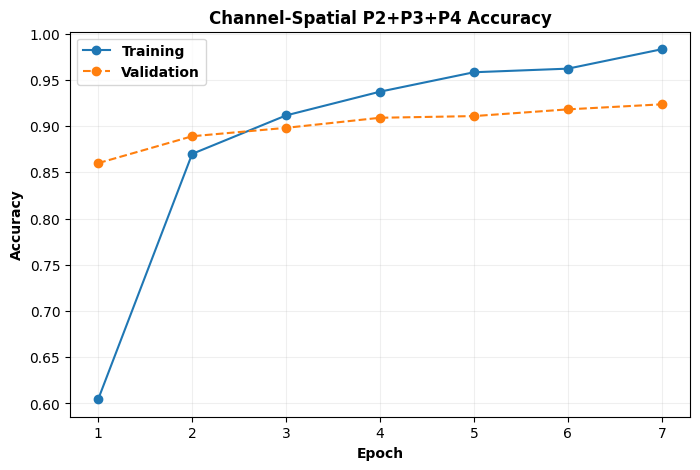

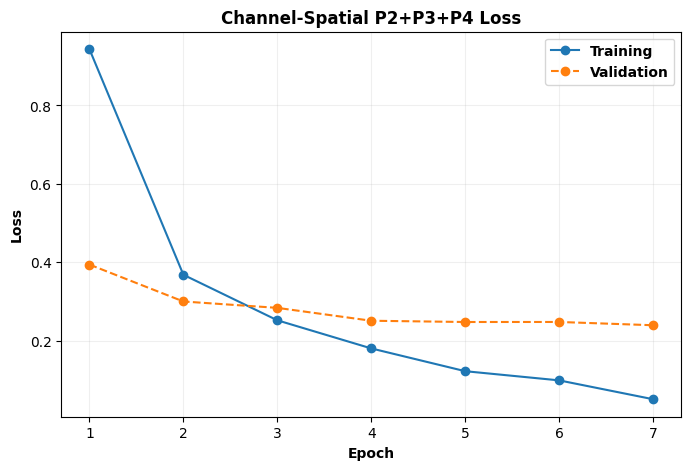

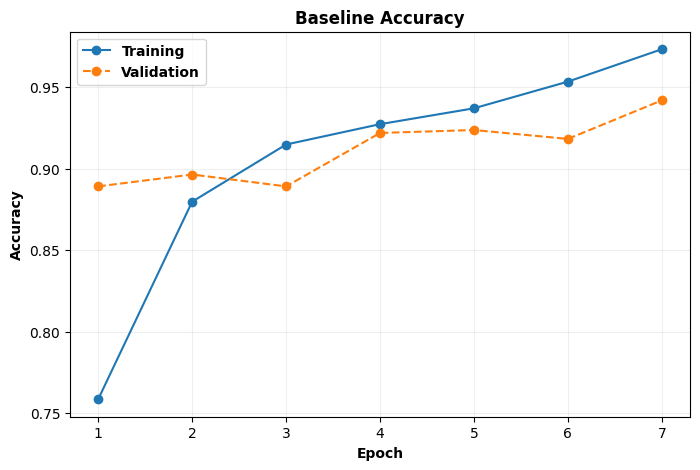

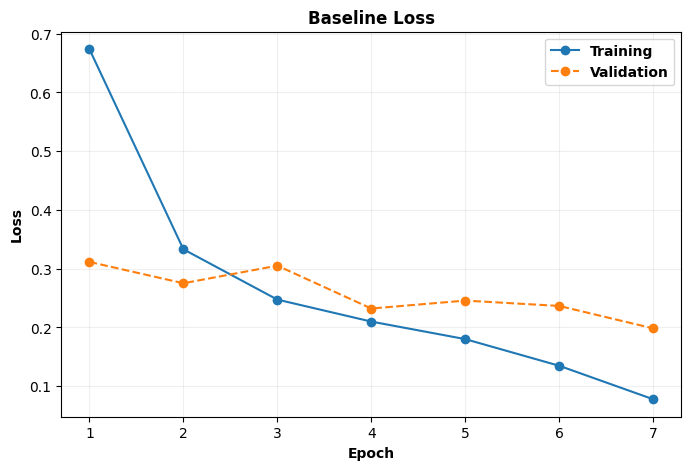

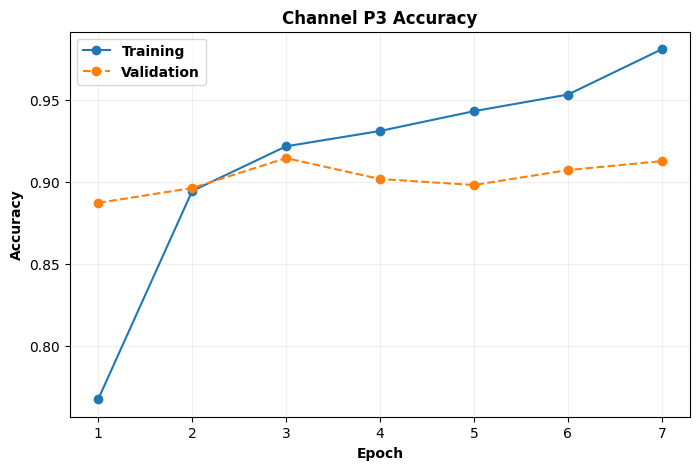

...

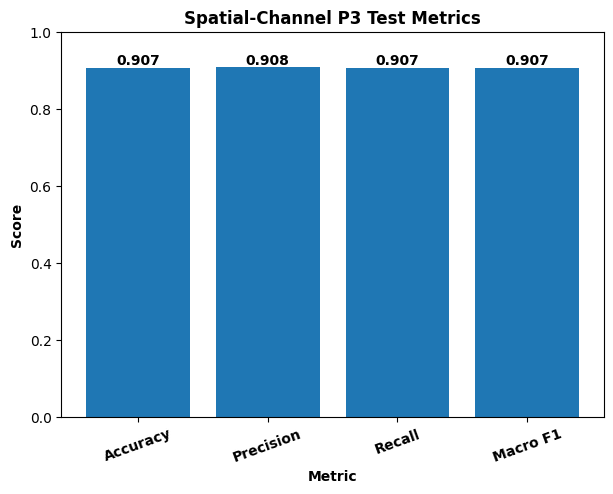

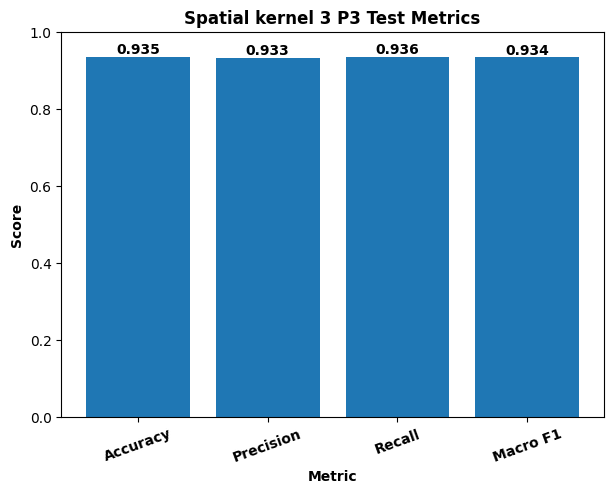

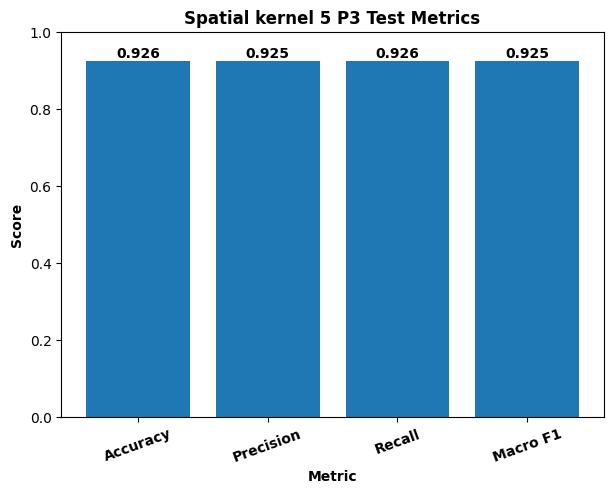

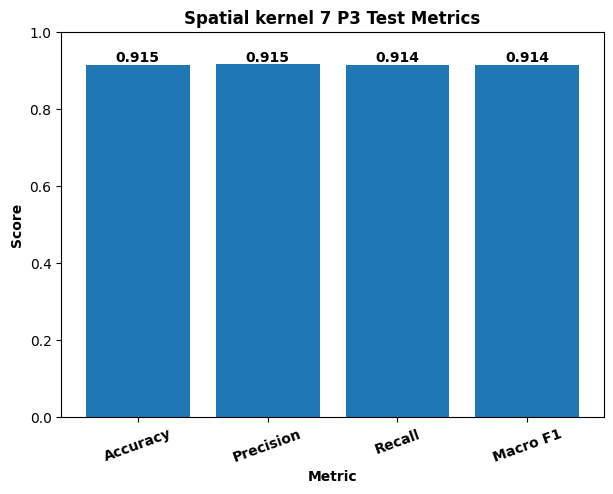

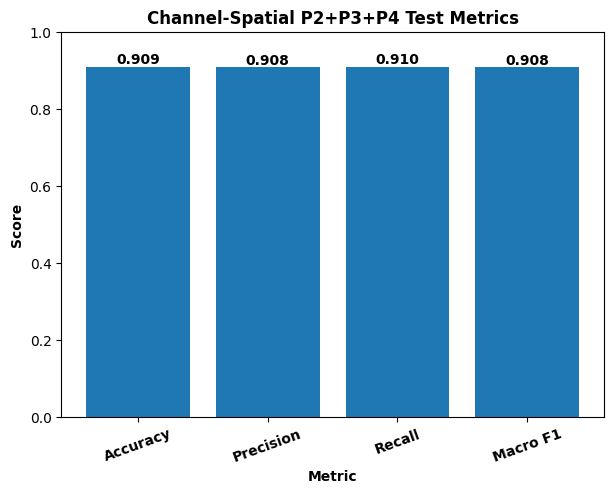

Separate training, validation, test-metric, and confusion-matrix figures saved in /content/drive/MyDrive/attention_experiment_outputs/plots


In [5]:
if rows:
    df = pd.DataFrame(rows)
    display(df)
    for model_name, history in histories.items():
        for metric, title in [('accuracy', 'Accuracy'), ('loss', 'Loss')]:
            figure, axis = plt.subplots(figsize=(8, 5))
            for key, style, label in [(metric, '-', 'Training'), ('val_' + metric, '--', 'Validation')]:
                if key in history:
                    axis.plot(range(1, len(history[key]) + 1), history[key], marker='o', linestyle=style, label=label)
            axis.set_title(model_name + ' ' + title, fontweight='bold')
            axis.set_xlabel('Epoch', fontweight='bold')
            axis.set_ylabel(title, fontweight='bold')
            axis.legend(prop={'weight': 'bold'})
            axis.grid(alpha=0.2)
            filename = model_name.lower().replace(' ', '_').replace('+', 'plus') + '_' + metric + '.png'
            savefig(figure, filename)
    for row in rows:
        metric_names = ['Accuracy', 'Precision', 'Recall', 'Macro F1']
        metric_values = [float(row[name]) for name in metric_names]
        figure, axis = plt.subplots(figsize=(7, 5))
        bars = axis.bar(metric_names, metric_values)
        axis.set_title(row['Model'] + ' Test Metrics', fontweight='bold')
        axis.set_xlabel('Metric', fontweight='bold')
        axis.set_ylabel('Score', fontweight='bold')
        axis.set_ylim(0, 1)
        axis.tick_params(axis='x', rotation=20)
        for tick in axis.get_xticklabels():
            tick.set_fontweight('bold')
        for bar, value in zip(bars, metric_values):
            axis.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.3f}', ha='center', va='bottom', fontweight='bold')
        filename = row['Model'].lower().replace(' ', '_').replace('+', 'plus') + '_test_metrics.png'
        savefig(figure, filename)
    print('Separate training, validation, test-metric, and confusion-matrix figures saved in', PLOTS)


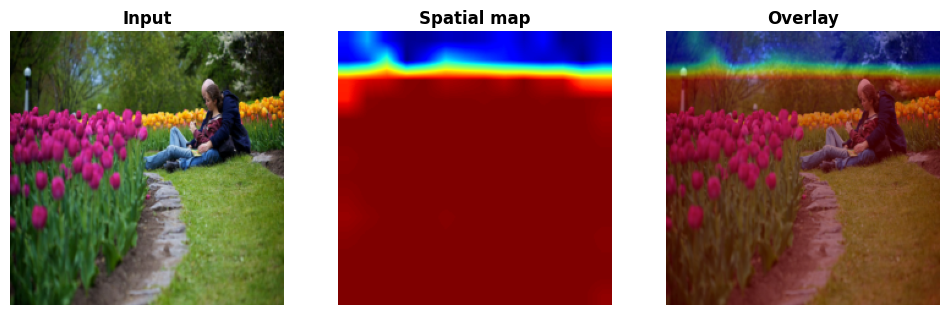

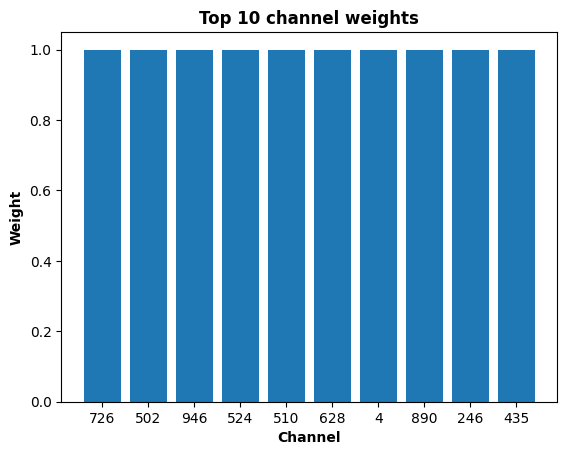

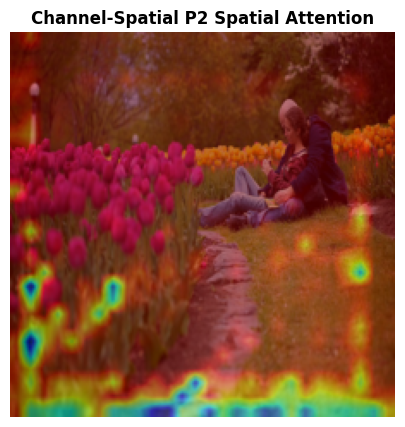

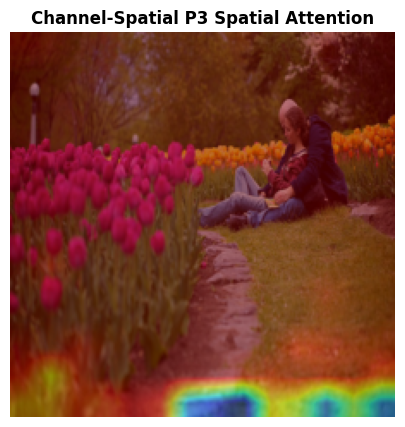

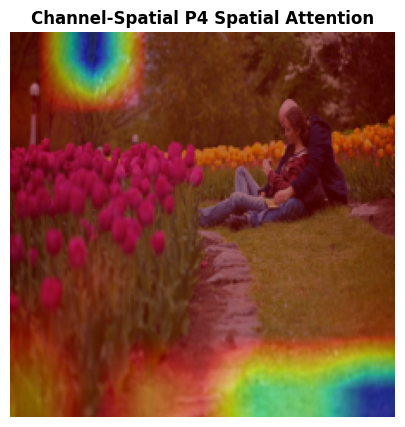

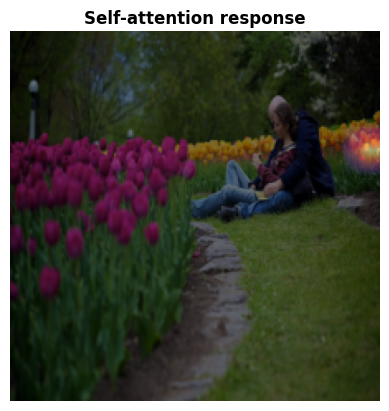

Plots saved in /content/drive/MyDrive/attention_experiment_outputs/plots


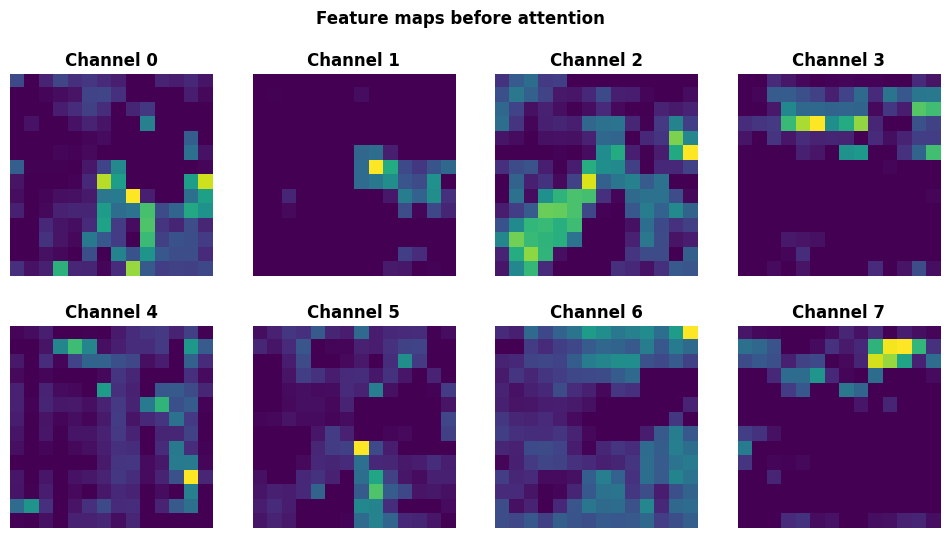

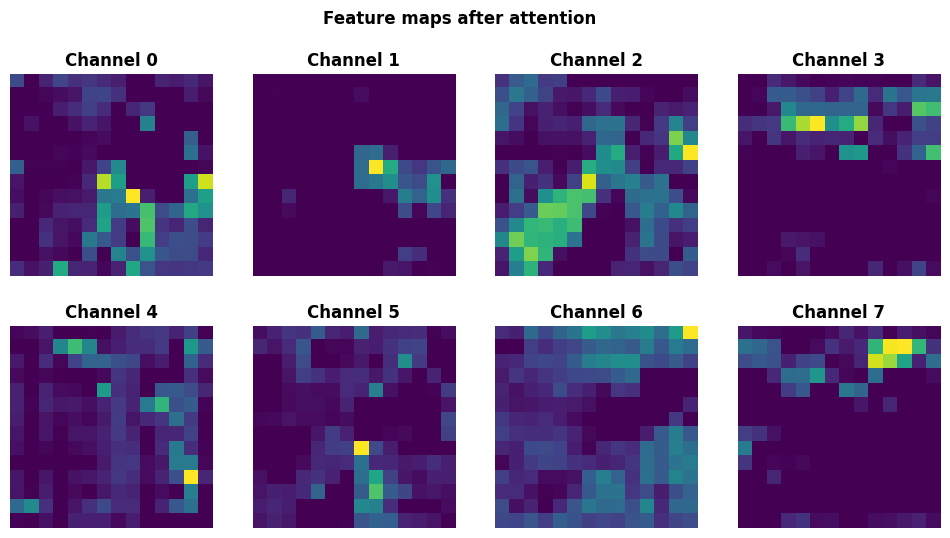

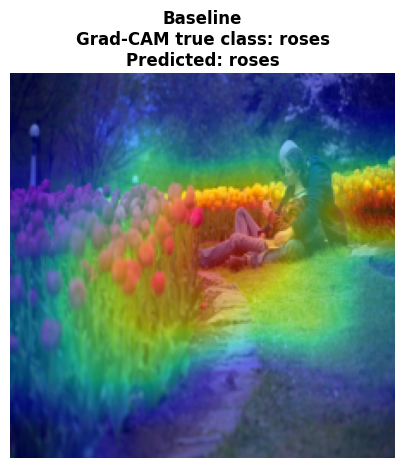

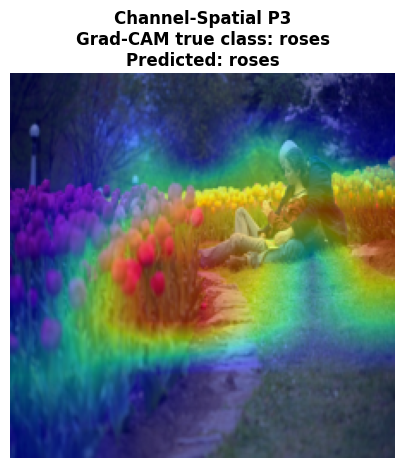

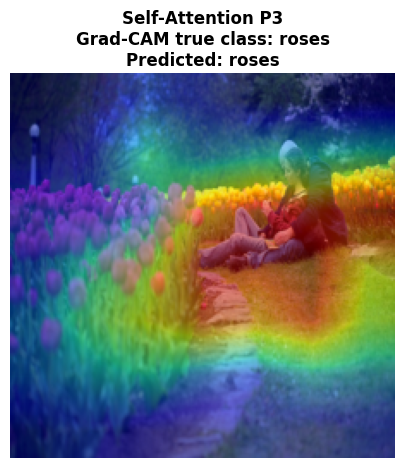

...

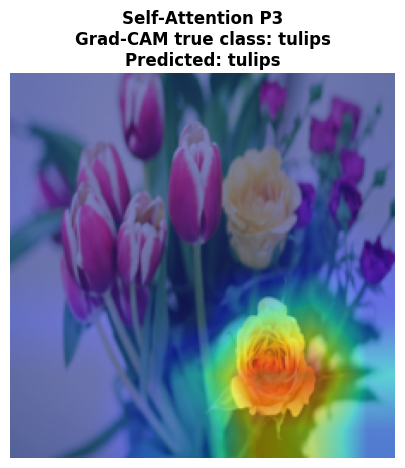

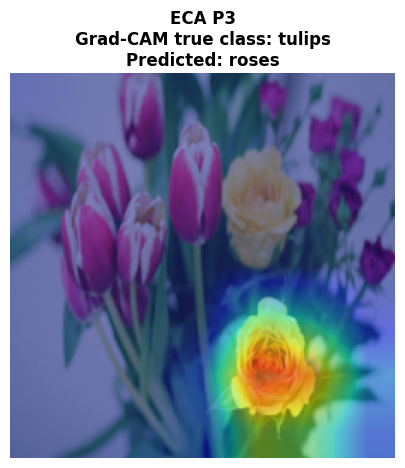

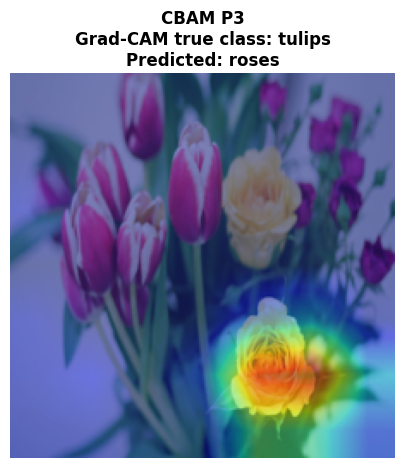

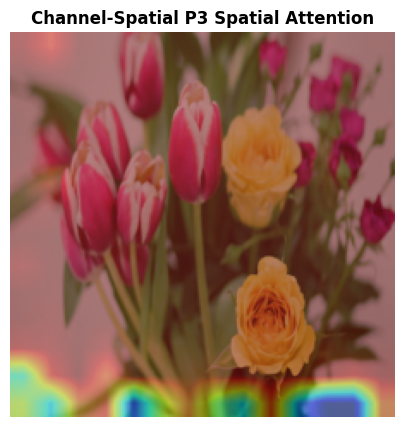

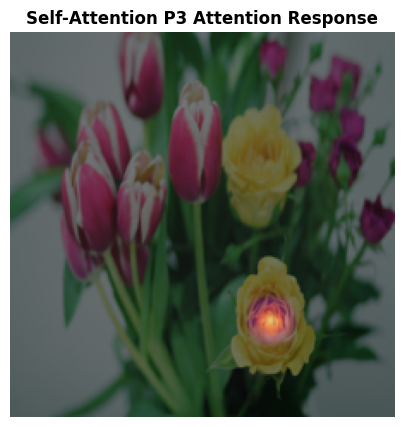

In [6]:
def xinput(i):
    return tf.keras.applications.resnet50.preprocess_input(tf.cast(X[i:i + 1], tf.float32))

def up(a):
    return tf.image.resize(a[..., None], (224, 224)).numpy()[..., 0]
rep = int(te[0])
if 'Channel-Spatial P3' in models:
    for j in te:
        if int(tf.argmax(models['Channel-Spatial P3'](xinput(j), training=False)[0])) == CLASS_LABELS[j]:
            rep = int(j)
            break
for n in ['Spatial P3', 'Channel-Spatial P3']:
    if n in models:
        m = models[n]
        l = next((z for z in m.layers if z.name == 'p3_cs_spatial_map' or z.name == 'p3_spatial_map'), None)
        if l:
            a = Model(m.input, l.output)(xinput(rep), training=False).numpy()[0, :, :, 0]
            a = up(a)
            f, ax = plt.subplots(1, 3, figsize=(12, 4))
            ax[0].imshow(X[rep])
            ax[0].set_title('Input', fontweight='bold')
            ax[1].imshow(a, cmap='jet')
            ax[1].set_title('Spatial map', fontweight='bold')
            ax[2].imshow(X[rep])
            ax[2].imshow(a, cmap='jet', alpha=0.45)
            ax[2].set_title('Overlay', fontweight='bold')
            for z in ax:
                z.axis('off')
            savefig(f, 'spatial_attention_overlay.png')
            break
if 'Channel P3' in models:
    m = models['Channel P3']
    l = next((z for z in m.layers if z.name == 'p3_channel_weights'), None)
    if l:
        w = Model(m.input, l.output)(xinput(rep), training=False).numpy().ravel()
        ix = np.argsort(w)[-10:][::-1]
        f, a = plt.subplots()
        a.bar([str(i) for i in ix], w[ix])
        a.set_title('Top 10 channel weights', fontweight='bold')
        a.set_xlabel('Channel', fontweight='bold')
        a.set_ylabel('Weight', fontweight='bold')
        savefig(f, 'channel_weights.png')
for position in [2, 3, 4]:
    model_name = 'Channel-Spatial P' + str(position)
    model = models.get(model_name)
    if model is None:
        continue
    map_layer = next((layer for layer in model.layers if layer.name == f'p{position}_cs_spatial_map'), None)
    if map_layer is None:
        continue
    spatial_map = Model(model.input, map_layer.output)(xinput(rep), training=False).numpy()[0, :, :, 0]
    figure, axis = plt.subplots(figsize=(6, 5))
    axis.imshow(X[rep])
    axis.imshow(up(spatial_map), cmap='jet', alpha=0.5)
    axis.set_title(model_name + ' Spatial Attention', fontweight='bold')
    axis.axis('off')
    savefig(figure, model_name.lower().replace(' ', '_') + '_spatial_attention.png')

def gradcam(model, image_id, class_id=None):
    graph_model = Model(model.input, [model.get_layer('last_stage_out').output, model.output])
    image = xinput(image_id)
    with tf.GradientTape() as tape:
        feature_maps, predictions = graph_model(image, training=False)
        selected_class = tf.argmax(predictions[0]) if class_id is None else tf.convert_to_tensor(class_id, dtype=tf.int64)
        score = tf.cast(tf.gather(predictions[0], selected_class), tf.float32) * 1024.0
    gradients = tape.gradient(score, feature_maps)
    gradients = tf.cast(gradients, tf.float32)
    feature_maps = tf.cast(feature_maps, tf.float32)
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * feature_maps, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-08)
    cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[0, :, :, 0]
    return (cam, int(selected_class.numpy()))
if 'Self-Attention P3' in models:
    m = models['Self-Attention P3']
    l = next((z for z in m.layers if z.name == 'p3_self_weights'), None)
    if l:
        a = Model(m.input, l.output)(xinput(rep), training=False).numpy()[0].mean(0).reshape(14, 14)
        a = up(a)
        f, ax = plt.subplots()
        ax.imshow(X[rep])
        ax.imshow(a, cmap='magma', alpha=0.5)
        ax.axis('off')
        ax.set_title('Self-attention response', fontweight='bold')
        savefig(f, 'self_attention_response.png')
print('Plots saved in', PLOTS)
if 'Channel-Spatial P3' in models:
    m = models['Channel-Spatial P3']
    before = m.get_layer('conv4_stage_out').output
    after = next((q.output for q in m.layers if q.name == 'p3_cs_spatial_scale'), None)
    if after is not None:
        b, a = Model(m.input, [before, after])(xinput(rep), training=False)
        for arr, title, file in [(b, 'Feature maps before attention', 'features_before_attention.png'), (a, 'Feature maps after attention', 'features_after_attention.png')]:
            f, axs = plt.subplots(2, 4, figsize=(12, 6))
            for j, ax in enumerate(axs.flat):
                ax.imshow(arr[0, :, :, j], cmap='viridis')
                ax.axis('off')
                ax.set_title('Channel ' + str(j), fontweight='bold')
            f.suptitle(title, fontweight='bold')
            savefig(f, file)

def spatial_attention_map(model, image_id):
    map_layer = model.get_layer('p3_cs_spatial_map')
    raw_map = Model(model.input, map_layer.output)(xinput(image_id), training=False).numpy()[0, :, :, 0]
    return up(raw_map)

def self_attention_map(model, image_id):
    weights_layer = model.get_layer('p3_self_weights')
    weights = Model(model.input, weights_layer.output)(xinput(image_id), training=False).numpy()[0]
    response = weights.mean(axis=0).reshape(14, 14)
    return up(response)
if all((name in models for name in ['Baseline', 'Channel-Spatial P3', 'Self-Attention P3', 'ECA P3', 'CBAM P3'])):
    correct_ids, incorrect_ids = ([], [])
    for image_id in te:
        baseline_prediction = int(tf.argmax(models['Baseline'](xinput(int(image_id)), training=False)[0]))
        if baseline_prediction == CLASS_LABELS[image_id] and len(correct_ids) < 3:
            correct_ids.append(int(image_id))
        elif baseline_prediction != CLASS_LABELS[image_id] and len(incorrect_ids) < 2:
            incorrect_ids.append(int(image_id))
        if len(correct_ids) == 3 and len(incorrect_ids) == 2:
            break
    gradcam_models = ['Baseline', 'Channel-Spatial P3', 'Self-Attention P3', 'ECA P3', 'CBAM P3']
    for sample_number, image_id in enumerate(correct_ids + incorrect_ids, start=1):
        for model_name in gradcam_models:
            cam, _ = gradcam(models[model_name], image_id, int(CLASS_LABELS[image_id]))
            predicted_class = int(tf.argmax(models[model_name](xinput(image_id), training=False)[0]))
            figure, axis = plt.subplots(figsize=(6, 5))
            axis.imshow(X[image_id])
            axis.imshow(cam, cmap='jet', alpha=0.45)
            axis.set_title(model_name + '\nGrad-CAM true class: ' + NAMES[int(CLASS_LABELS[image_id])] + '\nPredicted: ' + NAMES[predicted_class], fontweight='bold')
            axis.axis('off')
            filename = 'qualitative_sample_' + str(sample_number) + '_' + model_name.lower().replace(' ', '_').replace('+', 'plus') + '.png'
            savefig(figure, filename)
        spatial_map = spatial_attention_map(models['Channel-Spatial P3'], image_id)
        figure, axis = plt.subplots(figsize=(6, 5))
        axis.imshow(X[image_id])
        axis.imshow(spatial_map, cmap='jet', alpha=0.45)
        axis.set_title('Channel-Spatial P3 Spatial Attention', fontweight='bold')
        axis.axis('off')
        savefig(figure, 'qualitative_sample_' + str(sample_number) + '_channel_spatial_p3_spatial_attention.png')
        self_map = self_attention_map(models['Self-Attention P3'], image_id)
        figure, axis = plt.subplots(figsize=(6, 5))
        axis.imshow(X[image_id])
        axis.imshow(self_map, cmap='magma', alpha=0.5)
        axis.set_title('Self-Attention P3 Attention Response', fontweight='bold')
        axis.axis('off')
        savefig(figure, 'qualitative_sample_' + str(sample_number) + '_self_attention_p3_response.png')
else:
    missing = sorted({'Baseline', 'Channel-Spatial P3', 'Self-Attention P3', 'ECA P3', 'CBAM P3'} - set(models))
    print('Qualitative comparison skipped; required models are missing:', ', '.join(missing))


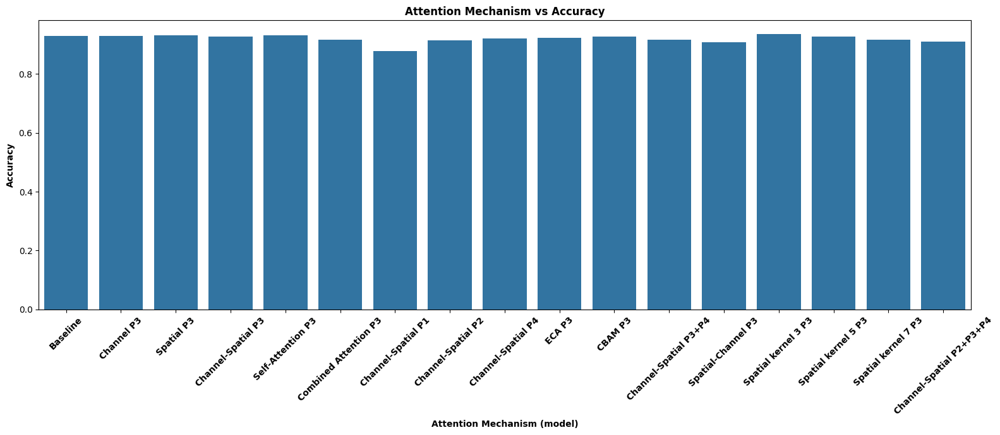

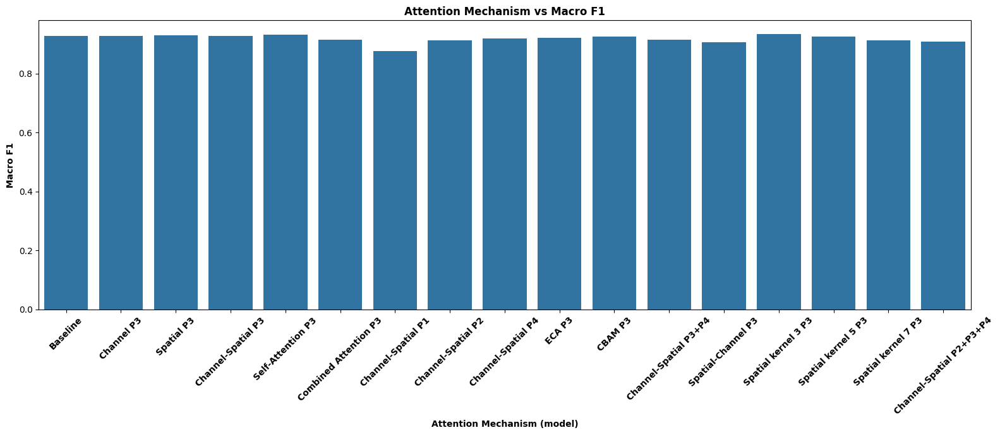

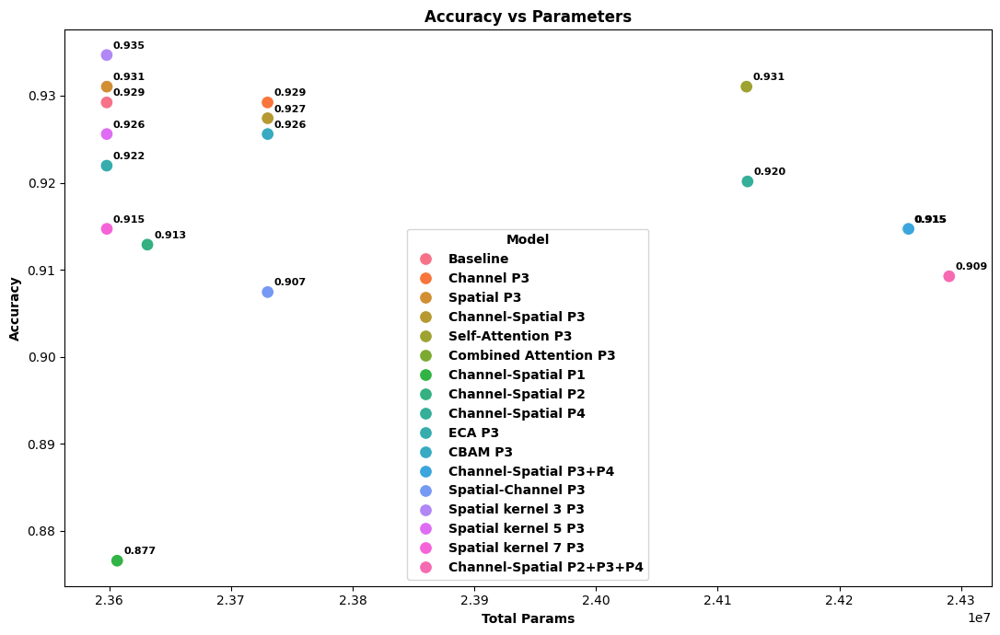

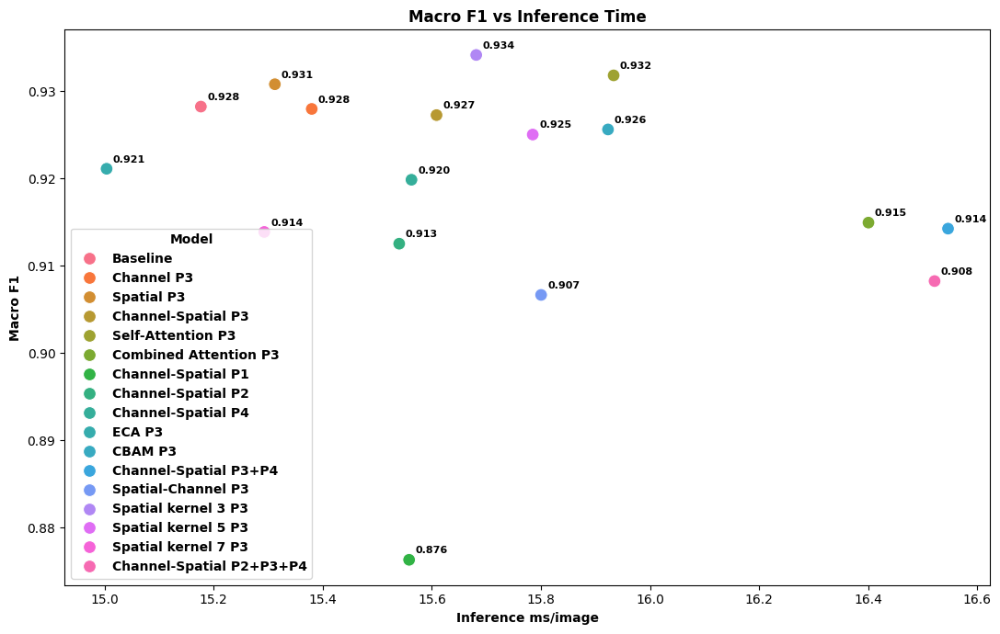

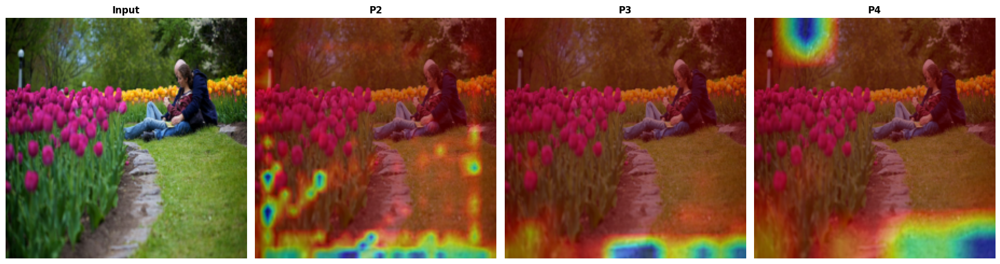

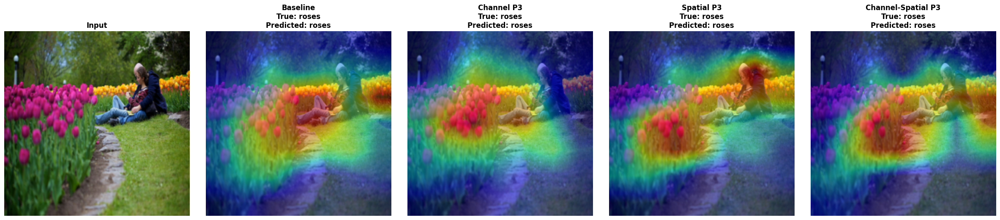

Comparison graphs and composite figures saved in: /content/drive/MyDrive/attention_experiment_outputs/plots


In [7]:
df = pd.DataFrame(rows)
PLOTS.mkdir(parents=True, exist_ok=True)

for column, title, filename in [
    ('Accuracy', 'Attention Mechanism vs Accuracy', 'comparison_mechanism_accuracy.png'),
    ('Macro F1', 'Attention Mechanism vs Macro F1', 'comparison_mechanism_macro_f1.png')
]:
    figure, axis = plt.subplots(figsize=(16, 7))
    sns.barplot(data=df, x='Model', y=column, ax=axis)
    axis.set_title(title, fontweight='bold')
    axis.set_xlabel('Attention Mechanism (model)', fontweight='bold')
    axis.set_ylabel(column, fontweight='bold')
    axis.tick_params(axis='x', rotation=45)
    for tick in axis.get_xticklabels():
        tick.set_fontweight('bold')
    figure.tight_layout()
    figure.savefig(PLOTS / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(figure)

for x_column, y_column, title, filename in [
    ('Total Params', 'Accuracy', 'Accuracy vs Parameters', 'comparison_accuracy_parameters.png'),
    ('Inference ms/image', 'Macro F1', 'Macro F1 vs Inference Time', 'comparison_macro_f1_inference_time.png')
]:
    figure, axis = plt.subplots(figsize=(11, 7))
    sns.scatterplot(data=df, x=x_column, y=y_column, hue='Model', s=100, ax=axis)

    for _, row in df.iterrows():
        axis.annotate(
            f"{float(row[y_column]):.3f}",
            (row[x_column], row[y_column]),
            xytext=(5, 5),
            textcoords='offset points',
            fontweight='bold',
            fontsize=8
        )

    axis.set_title(title, fontweight='bold')
    axis.set_xlabel(x_column, fontweight='bold')
    axis.set_ylabel(y_column, fontweight='bold')
    legend = axis.get_legend()
    if legend is not None:
        legend.set_title('Model', prop={'weight': 'bold'})
        for text in legend.get_texts():
            text.set_fontweight('bold')
    figure.tight_layout()
    figure.savefig(PLOTS / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(figure)

visual_specs = {
    'Spatial P3': ('spatial', (2,), 7, 'cs'),
    'Channel-Spatial P2': ('cs', (1,), 7, 'cs'),
    'Channel-Spatial P3': ('cs', (2,), 7, 'cs'),
    'Channel-Spatial P4': ('cs', (3,), 7, 'cs')
}

def get_visual_model(model_name):
    if model_name in models:
        return models[model_name]

    kind, positions, kernel, order = visual_specs[model_name]
    slug = model_name.lower().replace(' ', '_').replace('+', 'plus')
    checkpoint = CHECKPOINTS / (slug + '.weights.h5')

    if not checkpoint.exists():
        raise FileNotFoundError('Missing completed checkpoint: ' + str(checkpoint))

    visual_model = build(kind, positions, kernel, order, model_name)
    visual_model.load_weights(checkpoint)
    return visual_model

def visual_input(image_id):
    image = tf.cast(X[image_id:image_id + 1], tf.float32)
    return tf.keras.applications.resnet50.preprocess_input(image)

def resized_map(attention_map):
    return tf.image.resize(attention_map[..., None], (224, 224)).numpy()[..., 0]

def save_visual_figure(figure, filename):
    figure.tight_layout()
    figure.savefig(PLOTS / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(figure)

image_id = int(te[0])
true_class = int(CLASS_LABELS[image_id])
image_tensor = visual_input(image_id)

figure, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(X[image_id])
axes[0].set_title('Input', fontweight='bold')
axes[0].axis('off')

for axis, position in zip(axes[1:], [2, 3, 4]):
    model_name = 'Channel-Spatial P' + str(position)
    attention_model = get_visual_model(model_name)
    attention_layer = attention_model.get_layer(f'p{position}_cs_spatial_map')
    attention_output = Model(attention_model.input, attention_layer.output)
    attention_map = attention_output(image_tensor, training=False).numpy()[0, :, :, 0]

    axis.imshow(X[image_id])
    axis.imshow(resized_map(attention_map), cmap='jet', alpha=0.5)
    axis.set_title('P' + str(position), fontweight='bold')
    axis.axis('off')

save_visual_figure(figure, 'composite_input_p2_p3_p4.png')

mechanism_models = [
    ('Baseline', 'none', (), 7, 'cs'),
    ('Channel P3', 'channel', (2,), 7, 'cs'),
    ('Spatial P3', 'spatial', (2,), 7, 'cs'),
    ('Channel-Spatial P3', 'cs', (2,), 7, 'cs')
]

figure, axes = plt.subplots(1, 5, figsize=(24, 5))
axes[0].imshow(X[image_id])
axes[0].set_title('Input', fontweight='bold')
axes[0].axis('off')

for axis, (model_name, kind, positions, kernel, order) in zip(axes[1:], mechanism_models):
    if model_name in models:
        attention_model = models[model_name]
    else:
        slug = model_name.lower().replace(' ', '_').replace('+', 'plus')
        checkpoint = CHECKPOINTS / (slug + '.weights.h5')

        if not checkpoint.exists():
            raise FileNotFoundError('Missing completed checkpoint: ' + str(checkpoint))

        attention_model = build(kind, positions, kernel, order, model_name)
        attention_model.load_weights(checkpoint)

    graph_model = Model(
        attention_model.input,
        [attention_model.get_layer('last_stage_out').output, attention_model.output]
    )

    with tf.GradientTape() as tape:
        feature_maps, predictions = graph_model(image_tensor, training=False)
        score = tf.cast(predictions[0, true_class], tf.float32) * 1024.0

    gradients = tape.gradient(score, feature_maps)
    gradients = tf.cast(gradients, tf.float32)
    feature_maps = tf.cast(feature_maps, tf.float32)
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * feature_maps, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[0, :, :, 0]
    predicted_class = int(tf.argmax(predictions[0]))

    axis.imshow(X[image_id])
    axis.imshow(cam, cmap='jet', alpha=0.45)
    axis.set_title(
        model_name + '\nTrue: ' + NAMES[true_class] + '\nPredicted: ' + NAMES[predicted_class],
        fontweight='bold'
    )
    axis.axis('off')

save_visual_figure(
    figure,
    'composite_input_baseline_channel_spatial_channel_spatial.png'
)

print('Comparison graphs and composite figures saved in:', PLOTS)

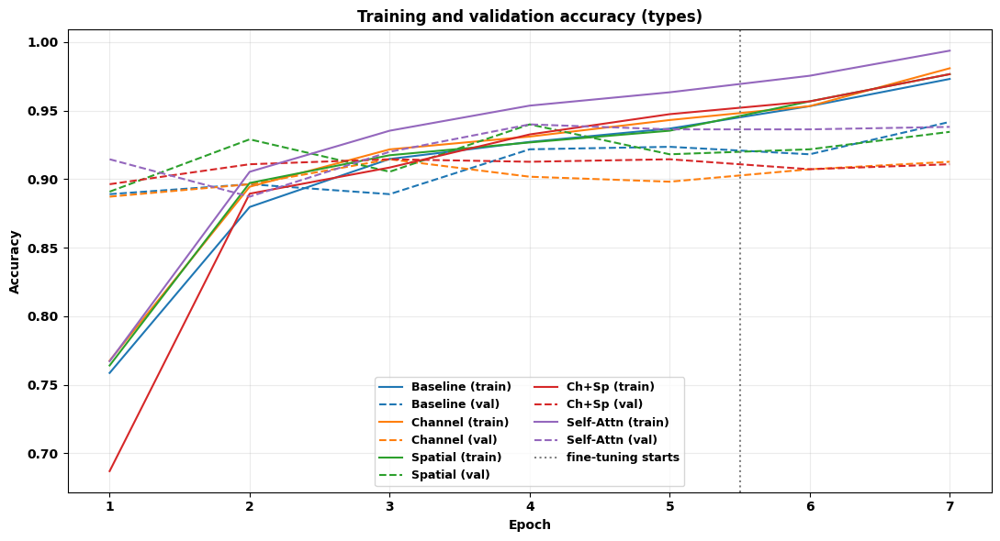

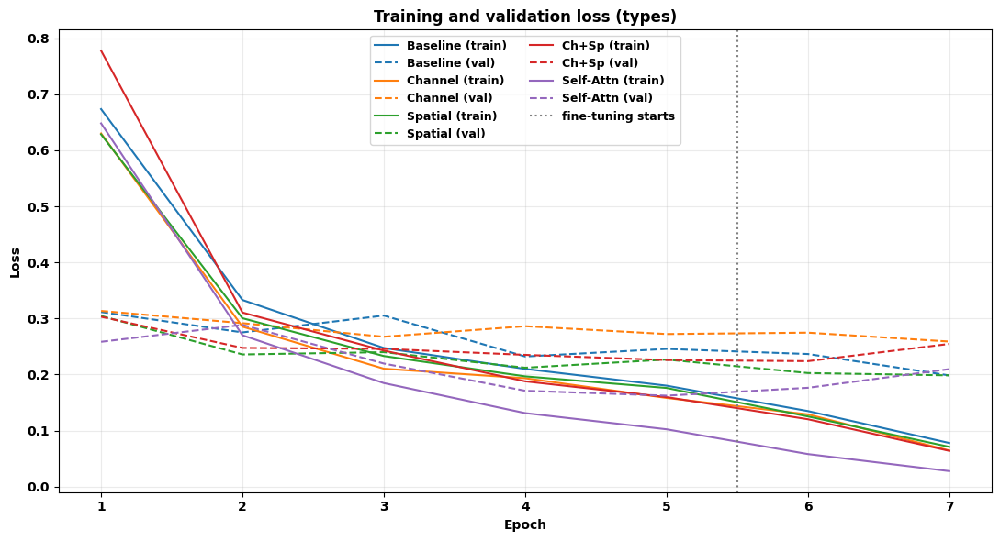

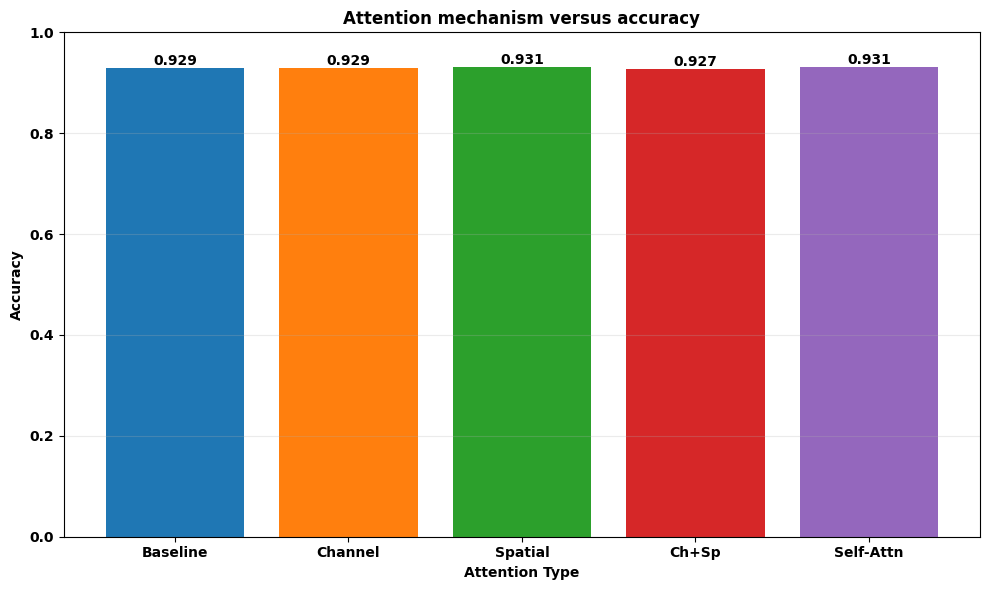

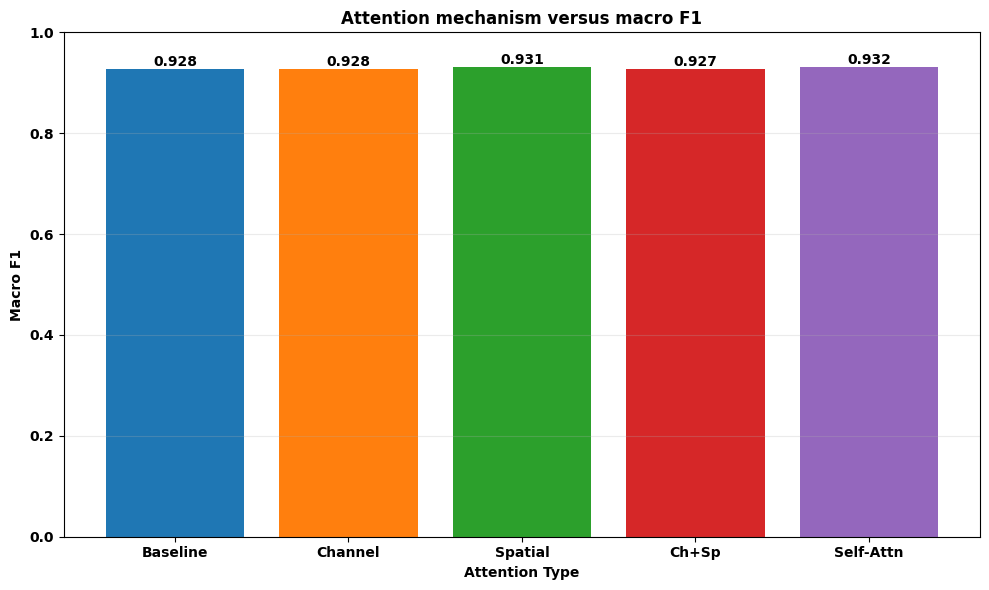

Section 11 plots saved in: /content/drive/MyDrive/attention_experiment_outputs/plots


In [9]:
# Section 11 plots: training curves and test-set mechanism comparisons.
PLOTS.mkdir(parents=True, exist_ok=True)

PLOT_MODELS = [
    ('Baseline', 'Baseline'),
    ('Channel P3', 'Channel'),
    ('Spatial P3', 'Spatial'),
    ('Channel-Spatial P3', 'Ch+Sp'),
    ('Self-Attention P3', 'Self-Attn'),
]
plot_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
model_colors = {name: plot_colors[i % len(plot_colors)] for i, (name, _) in enumerate(PLOT_MODELS)}

# 11.1 and 11.2: training and validation curves by attention type.
for metric, title, ylabel, filename in [
    ('accuracy', 'Training and validation accuracy (types)', 'Accuracy', 'section_11_1_accuracy_types.png'),
    ('loss', 'Training and validation loss (types)', 'Loss', 'section_11_2_loss_types.png'),
]:
    figure, axis = plt.subplots(figsize=(11, 6))
    plotted = 0

    for model_name, display_name in PLOT_MODELS:
        history = histories.get(model_name)
        if not history:
            continue

        for key, style, split_name in [
            (metric, '-', 'train'),
            ('val_' + metric, '--', 'val'),
        ]:
            values = history.get(key)
            if values:
                axis.plot(
                    range(1, len(values) + 1),
                    values,
                    linestyle=style,
                    color=model_colors[model_name],
                    label=f'{display_name} ({split_name})',
                )
                plotted += 1

    if plotted == 0:
        plt.close(figure)
        print('No training histories found. Run the experiment cell first.')
    else:
        axis.axvline(
            FROZEN_EPOCHS + 0.5,
            color='gray',
            linestyle=':',
            linewidth=1.5,
            label='fine-tuning starts',
        )
        axis.set_title(title, fontweight='bold')
        axis.set_xlabel('Epoch', fontweight='bold')
        axis.set_ylabel(ylabel, fontweight='bold')
        axis.grid(True, alpha=0.25)

        legend = axis.legend(loc='best', fontsize=9, ncol=2)
        for text in legend.get_texts():
            text.set_fontweight('bold')
        for tick in axis.get_xticklabels() + axis.get_yticklabels():
            tick.set_fontweight('bold')

        figure.tight_layout()
        savefig(figure, filename)

# 11.3 and 11.4: test-set accuracy and macro F1 for the same attention types.
results = pd.DataFrame(rows)
if not results.empty:
    selected_names = [name for name, _ in PLOT_MODELS]
    results = results[results['Model'].isin(selected_names)].copy()
    display_names = dict(PLOT_MODELS)
    results['Attention Type'] = results['Model'].map(display_names)

    for metric, title, filename in [
        ('Accuracy', 'Attention mechanism versus accuracy', 'section_11_3_mechanism_accuracy.png'),
        ('Macro F1', 'Attention mechanism versus macro F1', 'section_11_4_mechanism_macro_f1.png'),
    ]:
        available = results.dropna(subset=[metric]) if metric in results else pd.DataFrame()
        if available.empty:
            print(f'No recorded {metric} results found for the selected attention types.')
            continue

        figure, axis = plt.subplots(figsize=(10, 6))
        bars = axis.bar(
            available['Attention Type'],
            available[metric].astype(float),
            color=[model_colors[name] for name in available['Model']],
        )
        axis.set_title(title, fontweight='bold')
        axis.set_xlabel('Attention Type', fontweight='bold')
        axis.set_ylabel(metric, fontweight='bold')
        axis.set_ylim(0, 1)
        axis.grid(axis='y', alpha=0.25)

        for tick in axis.get_xticklabels() + axis.get_yticklabels():
            tick.set_fontweight('bold')

        for bar, value in zip(bars, available[metric].astype(float)):
            axis.text(
                bar.get_x() + bar.get_width() / 2,
                value,
                f'{value:.3f}',
                ha='center',
                va='bottom',
                fontweight='bold',
            )

        figure.tight_layout()
        savefig(figure, filename)
else:
    print('No recorded test metrics found. Run the experiment cell first.')

print('Section 11 plots saved in:', PLOTS)

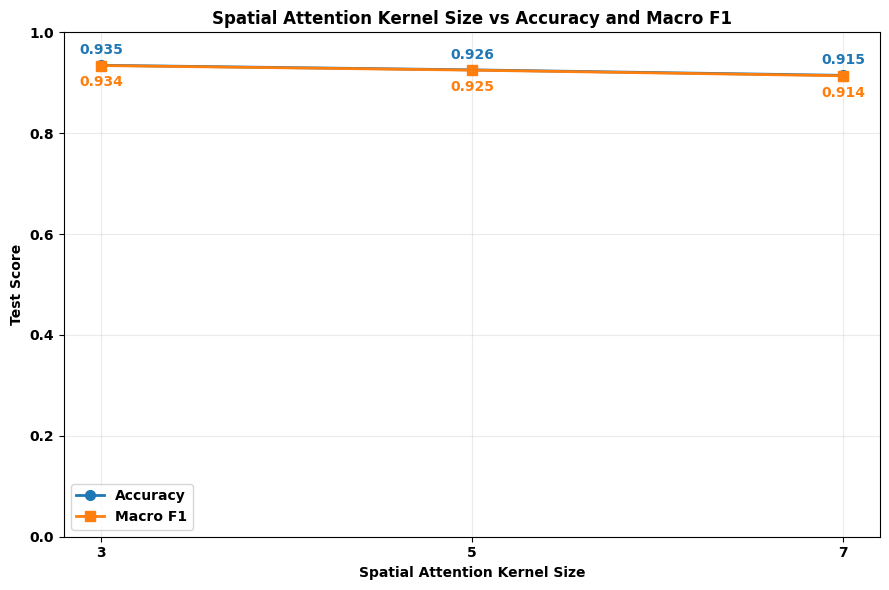

In [10]:
# 11.5: Spatial attention kernel size versus test accuracy and macro F1.
KERNEL_MODEL_NAMES = {
    3: 'Spatial kernel 3 P3',
    5: 'Spatial kernel 5 P3',
    7: 'Spatial kernel 7 P3',
}

kernel_rows = pd.DataFrame(rows)
if not kernel_rows.empty:
    kernel_rows = kernel_rows[
        kernel_rows['Model'].isin(KERNEL_MODEL_NAMES.values())
    ].copy()

    if not kernel_rows.empty:
        kernel_rows['Kernel Size'] = pd.to_numeric(
            kernel_rows['Kernel'], errors='coerce'
        )
        kernel_rows = (
            kernel_rows
            .dropna(subset=['Kernel Size'])
            .sort_values('Kernel Size')
        )

if kernel_rows.empty:
    print(
        'No recorded spatial-kernel results found. '
        'Run the 3x3, 5x5, and 7x7 spatial models first.'
    )
else:
    figure, axis = plt.subplots(figsize=(9, 6))

    for metric, marker, color in [
        ('Accuracy', 'o', 'tab:blue'),
        ('Macro F1', 's', 'tab:orange'),
    ]:
        values = kernel_rows[metric].astype(float)
        axis.plot(
            kernel_rows['Kernel Size'],
            values,
            marker=marker,
            linewidth=2,
            markersize=7,
            color=color,
            label=metric,
        )

        vertical_offset = 8 if metric == 'Accuracy' else -15
        for kernel_size, value in zip(kernel_rows['Kernel Size'], values):
            axis.annotate(
                f'{value:.3f}',
                (kernel_size, value),
                xytext=(0, vertical_offset),
                textcoords='offset points',
                ha='center',
                fontweight='bold',
                color=color,
            )

    axis.set_title(
        'Spatial Attention Kernel Size vs Accuracy and Macro F1',
        fontweight='bold',
    )
    axis.set_xlabel('Spatial Attention Kernel Size', fontweight='bold')
    axis.set_ylabel('Test Score', fontweight='bold')
    axis.set_xticks(sorted(kernel_rows['Kernel Size'].astype(int).unique()))
    axis.set_ylim(0, 1)
    axis.grid(True, alpha=0.25)

    legend = axis.legend()
    for text in legend.get_texts():
        text.set_fontweight('bold')
    for tick in axis.get_xticklabels() + axis.get_yticklabels():
        tick.set_fontweight('bold')

    figure.tight_layout()
    savefig(figure, 'section_11_5_spatial_kernel_size_metrics.png')

Run cells in order. Colab outputs live under `/content/drive/MyDrive/attention_experiment_outputs/`, with every plot in the `plots` folder. Outputs and completed-model checkpoints persist in Google Drive at My Drive/attention_experiment_outputs.
